# Expansion history and cosmic acceleration from 30 cosmic chronometers

These are real **derived** differential-age expansion rates, not raw galaxy spectra or ages. All30 chronometers are reconstructed. The18 mixed-BAO rows in the historical author file are a separate acquisition, archived only. No actual acceleration truth exists. Gray curves are independent original GaPP runs; colored curves are fresh local calculations.

Differential ages measure $H(z)=-(1+z)^{-1}dz/dt$. The inverse relationship is
$$H(z)=H_0\exp\left[\int_0^z\frac{1+q(u)}{1+u}\,du\right],\qquad q(z)=(1+z)H'(z)/H(z)-1.$$
Here z,u are dimensionless redshift, t cosmic time, H the expansion rate in km/s/Mpc, prime the redshift derivative, and negative q acceleration. Differentiation and extrapolation to z=0 are weakly constrained.

The explicit GP forms $A=K+\mathrm{diag}(\sigma_i^2)=LL^T$ and minimizes $y^TA^{-1}y/2+\sum_i\log L_{ii}+N\log(2\pi)/2$, with analytic gradients and original TNC conventions. Kernel derivatives yield per-point covariance C of (H,H prime). These are separate 2 by 2 marginals, not a covariance across redshift. Delta-method q variance is $JCJ^T$ with $J=(-(1+z)H'/H^2,(1+z)/H)$. Conditional bands omit hyperparameter and stellar-population systematics and are not physical confidence intervals.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
# Maintainer figure export; robust before/after tasks/domain/task migration.
tasks_dir=next(p for p in root.parents if p.name=='tasks')
configured_export=os.environ.get('IMAGING_REVIEW_EXPORT_DIR') or os.environ.get('IMAGING_REVIEW_DIR')
review_export_dir=Path(configured_export) if configured_export else tasks_dir.parent.parent/'imaging-101-maintainer'/'benchmark_readiness_20261029'/'notebook_exports'/root.name
review_export_dir.mkdir(parents=True,exist_ok=True)
from src.solvers import reconstruct
from src.preprocessing import load_observations,reconstruction_grid
from src.physics_model import KERNELS,q_delta_standard_deviation
from evaluation.judge import evaluate
from src.visualization import save_review_figure
started=time.perf_counter();fresh,records=reconstruct();seconds=time.perf_counter()-started
report=evaluate(fresh)
assert report['passed'],report
with np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:original={k:f[k] for k in f.files}
np.savez('notebooks/reference_outputs/fresh_measurements.npz',**fresh)
z,y,error=load_observations();grid=reconstruction_grid()
print('Fresh full four-kernel seconds:',seconds,'Python:',sys.executable)
print(json.dumps(report,indent=2))
for i,kernel in enumerate(KERNELS):print(kernel,'fresh H0:',fresh['hubble_constant'][0,i],'original H0:',original['hubble_constant'][0,i],'NLL:',records[i]['negative_log_likelihood'])


Fresh full four-kernel seconds: 0.017693599918857217 Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "maximum_q_absolute_error": 7.38660304022698e-06,
    "maximum_H_relative_error": 1.278101601065748e-06,
    "maximum_Hprime_sigma_normalized_error": 2.3787344674457122e-05,
    "maximum_covariance_sigma_normalized_error": 2.7389640475437475e-05,
    "q_identity_error": 0.0,
    "H0_identity_relative_error": 0.0,
    "observation_standardized_rms": 0.689033225185066
  },
  "thresholds": {
    "maximum_q_absolute_error": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "maximum_H_relative_error": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "maximum_Hprime_sigma_normalized_error": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "maximum_covariance_sigma_normalized_error": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "q_ide

## What rate observations constrain

Shaded intervals are conditional one-standard-deviation marginals. Solid colored curves are fresh; dashed gray curves are original. All kernels use the same30 observations and errors. Derivative uncertainty increases where observational support weakens.

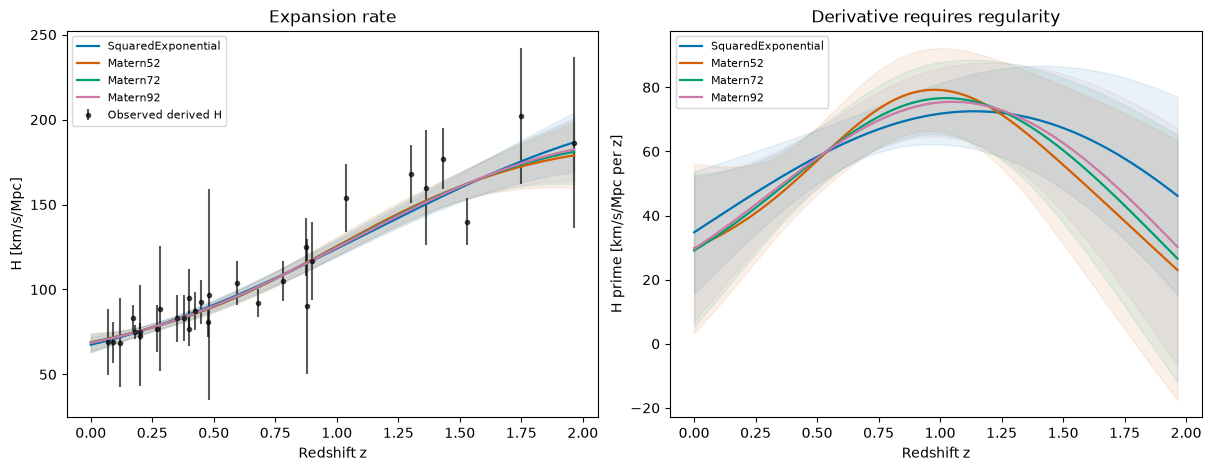

In [2]:
colors=['#0072B2','#D55E00','#009E73','#CC79A7']
fig,axes=plt.subplots(1,2,figsize=(12,4.6),layout='constrained')
axes[0].errorbar(z,y,yerr=error,fmt='o',ms=3,color='black',alpha=.65,label='Observed derived H')
for i,(name,color) in enumerate(zip(KERNELS,colors)):
    h=fresh['hubble_rate'][0,i];hp=fresh['hubble_derivative'][0,i];c=fresh['point_covariance'][0,i]
    for ax,mean,variance,key in [(axes[0],h,c[:,0,0],'hubble_rate'),(axes[1],hp,c[:,1,1],'hubble_derivative')]:
        ax.fill_between(grid,mean-np.sqrt(variance),mean+np.sqrt(variance),color=color,alpha=.09)
        ax.plot(grid,original[key][0,i],'--',color='.45',lw=1)
        ax.plot(grid,mean,color=color,lw=1.6,label=name)
axes[0].set(ylabel='H [km/s/Mpc]',xlabel='Redshift z',title='Expansion rate')
axes[1].set(ylabel='H prime [km/s/Mpc per z]',xlabel='Redshift z',title='Derivative requires regularity')
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
save_review_figure(fig,str(review_export_dir/'gapp_rate_derivative.png'));plt.show()


## Acceleration and the present expansion rate

Wide high-redshift delta-method bands and kernel dependence show weak identification. Smooth high-z means do not establish a measured cosmic transition. H0 is an extrapolation; its error bars show conditional GP uncertainty. Black crosses denote original values.

SquaredExponential q0, sigma0, qmaxz, sigma_maxz: -0.4846635107948075 0.31442053737353426 -0.2669278371331111 0.433030606390685
Matern52 q0, sigma0, qmaxz, sigma_maxz: -0.5675648665401217 0.4129384867626659 -0.6189244610941945 0.6385287219284513
Matern72 q0, sigma0, qmaxz, sigma_maxz: -0.5767804324673989 0.3723676356193807 -0.5651033591927069 0.593960738194689
Matern92 q0, sigma0, qmaxz, sigma_maxz: -0.5683706813358119 0.35428058657691763 -0.5091368565743846 0.5603427054165443


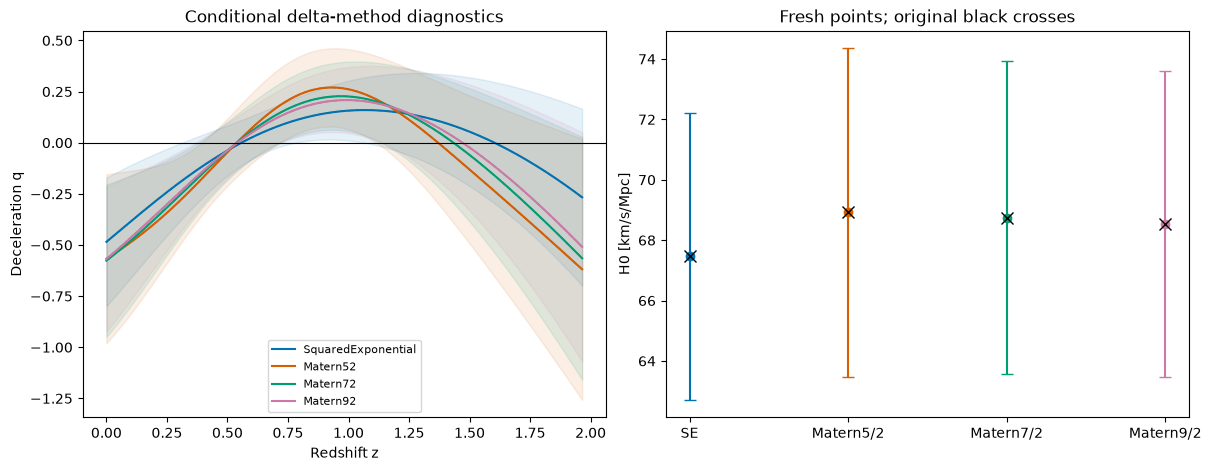

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.6),layout='constrained')
for i,(name,color) in enumerate(zip(KERNELS,colors)):
    h=fresh['hubble_rate'][0,i];hp=fresh['hubble_derivative'][0,i];c=fresh['point_covariance'][0,i];q=fresh['reconstruction'][0,i]
    sigma=q_delta_standard_deviation(grid,h,hp,c)
    axes[0].fill_between(grid,q-sigma,q+sigma,color=color,alpha=.10)
    axes[0].plot(grid,original['reconstruction'][0,i],'--',color='.4',lw=1)
    axes[0].plot(grid,q,color=color,label=name)
    axes[1].errorbar(i,h[0],yerr=np.sqrt(c[0,0,0]),fmt='o',color=color,capsize=4)
    axes[1].plot(i,original['hubble_constant'][0,i],'x',color='black',ms=8,zorder=5)
    print(name,'q0, sigma0, qmaxz, sigma_maxz:',q[0],sigma[0],q[-1],sigma[-1])
axes[0].axhline(0,color='black',lw=.8);axes[0].set(xlabel='Redshift z',ylabel='Deceleration q',title='Conditional delta-method diagnostics')
axes[0].legend(fontsize=8)
axes[1].set(xticks=range(4),xticklabels=['SE','Matern5/2','Matern7/2','Matern9/2'],ylabel='H0 [km/s/Mpc]',title='Fresh points; original black crosses')
save_review_figure(fig,str(review_export_dir/'gapp_acceleration.png'));plt.show()


## Actual initialization experiment

Repeat the complete inverse with initial hyperparameters scaled by0.5 and2, retaining original positive bounds and all observations. This measures numerical basin stability, not physical uncertainty. The twelve independent original fits preceded local extraction and set finite numerical tolerances.

Initial factor 0.5 max q change 3.521290551022904e-05 max H change 0.0009330506323976806
Initial factor 2.0 max q change 8.488638817716332e-05 max H change 0.0014605253727495437


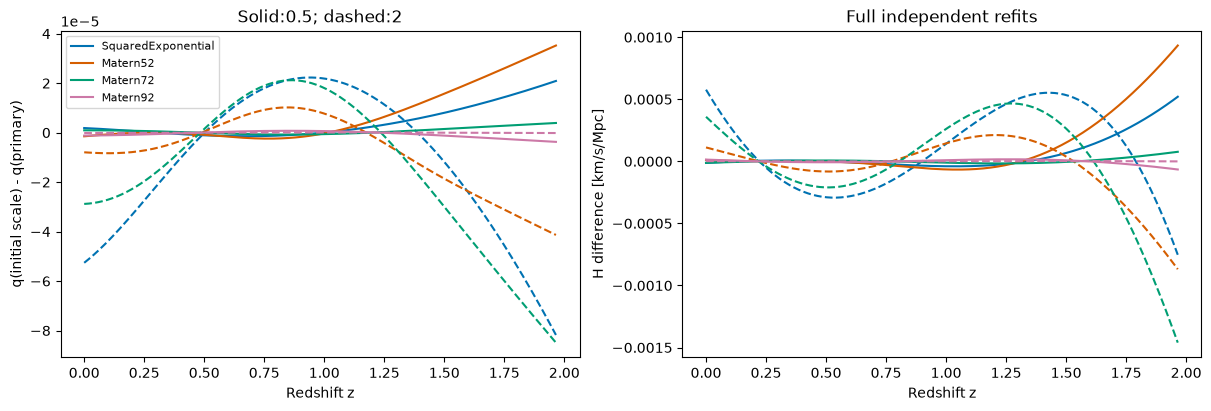

Numerical parity and initialization stability pass. Physical inference remains limited by observations, conditional uncertainty and kernel regularity.


In [4]:
experiments={}
for factor in [.5,2.]:
    result,metadata=reconstruct(initial_factor=factor);experiments[factor]=result
    print('Initial factor',factor,'max q change',np.max(abs(result['reconstruction']-fresh['reconstruction'])),'max H change',np.max(abs(result['hubble_rate']-fresh['hubble_rate'])))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i,(name,color) in enumerate(zip(KERNELS,colors)):
    for factor,style in [(.5,'-'),(2.,'--')]:
        result=experiments[factor]
        axes[0].plot(grid,result['reconstruction'][0,i]-fresh['reconstruction'][0,i],style,color=color,label=name if factor==.5 else None)
        axes[1].plot(grid,result['hubble_rate'][0,i]-fresh['hubble_rate'][0,i],style,color=color)
axes[0].set(xlabel='Redshift z',ylabel='q(initial scale) - q(primary)',title='Solid:0.5; dashed:2')
axes[1].set(xlabel='Redshift z',ylabel='H difference [km/s/Mpc]',title='Full independent refits')
axes[0].legend(fontsize=8)
save_review_figure(fig,str(review_export_dir/'gapp_initialization.png'));plt.show()
print('Numerical parity and initialization stability pass. Physical inference remains limited by observations, conditional uncertainty and kernel regularity.')


## Nonlinear uncertainty check

The paper recommends pointwise Monte Carlo when ratio uncertainties are appreciable. Draw the full correlated pair (H,H prime) at selected redshifts and compare conditional quantiles with the delta approximation. Negative-H draws, if any, are counted and retained: no hidden positivity truncation is applied. These are conditional model diagnostics, not physical confidence intervals, and there is no cross-redshift realization.

In [5]:
rng=np.random.default_rng(20261029)
print('kernel,z, delta sigma, conditional MC q 16/50/84 percentiles, negative-H count')
for i,name in enumerate(KERNELS):
    for j in [0,100,199]:
        mean=np.array([fresh['hubble_rate'][0,i,j],fresh['hubble_derivative'][0,i,j]])
        c=fresh['point_covariance'][0,i,j]
        draws=rng.multivariate_normal(mean,c,size=50000)
        ratios=(1+grid[j])*draws[:,1]/draws[:,0]-1
        sigma=q_delta_standard_deviation(grid[j],mean[0],mean[1],c)
        print(name,float(grid[j]),float(sigma),np.quantile(ratios,[.16,.5,.84]).tolist(),int(np.sum(draws[:,0]<=0)))


kernel,z, delta sigma, conditional MC q 16/50/84 percentiles, negative-H count
SquaredExponential 0.0 0.31442053737353426 [-0.7794637936569452, -0.48667814943530086, -0.15420019773613952] 0
SquaredExponential 0.9874371859296482 0.1438760133605623 [0.01299656582587627, 0.15490120296318455, 0.2989181445906738] 0
SquaredExponential 1.965 0.433030606390685 [-0.728134130538227, -0.25979357420733146, 0.13684239967340844] 0
Matern52 0.0 0.4129384867626659 [-0.953651037882166, -0.5693845656430081, -0.13231637056145298] 0
Matern52 0.9874371859296482 0.19495271286049934 [0.06901730614717763, 0.26430709467309843, 0.4552018071632514] 0
Matern52 1.965 0.6385287219284513 [-1.3030536418346121, -0.6128888165998396, -0.031667273049135566] 0
Matern72 0.0 0.37236763561938074 [-0.9239467751438897, -0.577157876999385, -0.17767460559625184] 0
Matern72 0.9874371859296482 0.16875805646324926 [0.05995644227767256, 0.22800956034436548, 0.39429922095061887] 0
Matern72 1.965 0.5939607381946889 [-1.211393502915821